# Лабораторная работа №7
## «Нечёткие модели надёжности»

**Студент:** Пермяков Дмитрий Кириллович, ИУ5-22М
**Вариант:** 18

---

### Суть
Берём данные из ЛР6, **«размываем» каждое число** в гауссово нечёткое число (среднее = само число, СКО = 10% от него), пропускаем через те же формулы Джелински–Моранды и Ла Падула — и смотрим, насколько устойчив результат к неопределённости исходных данных.

### Задание
«По данным лабораторных работ 6 и 7 обобщить числовые данные на нечёткие числа в виде нормального закона с коэффициентом вариации 0.1 и выполнить расчёт нечёткой модели надёжности системы.»


In [1]:
import numpy as np
import matplotlib.pyplot as plt

VARIANT = 18
CV = 0.1      # коэффициент вариации: σ = CV * центр
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

T_orig = np.array([29, 30, 34, 33, 38, 37, 40, 44, 46, 45], dtype=float)   # J-M: интервалы между отказами
m_orig = np.array([2, 23, 22, 27, 20, 16, 23, 4, 14, 6], dtype=float)   # Ла Падула: число отказов
print('Чёткие T:', T_orig.tolist())
print('Чёткие m:', m_orig.tolist())


Чёткие T: [29.0, 30.0, 34.0, 33.0, 38.0, 37.0, 40.0, 44.0, 46.0, 45.0]
Чёткие m: [2.0, 23.0, 22.0, 27.0, 20.0, 16.0, 23.0, 4.0, 14.0, 6.0]


## Идея «нечёткого числа»

Каждое число $x$ заменяем на **функцию принадлежности** гауссова вида:
$$\mu(t) = \exp\!\Big(-\dfrac{(t-x)^2}{2\sigma^2}\Big),\qquad \sigma = 0.1\cdot x.$$

В вероятностной интерпретации это $\mathcal{N}(x,\sigma)$. Если параметры — нечёткие, то и результат расчёта тоже будет нечётким. Чтобы получить функцию принадлежности результата, удобнее всего применить **Монте-Карло**: $N$ раз сэмплируем все входы из их распределений, считаем выход, получаем гистограмму.

Это и есть «принцип обобщения» из методички — на каждой паре входных значений делаем минимум, потом собираем результат.

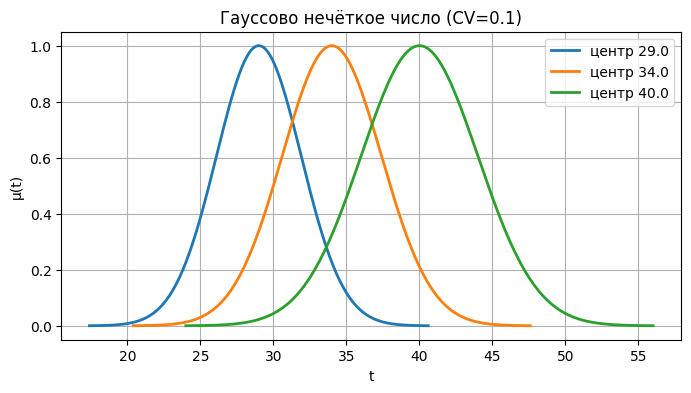

In [2]:
# Визуализация одного нечёткого числа
plt.figure(figsize=(8,4))
for x in [29.0, 34.0, 40.0]:
    sigma = CV*x
    tt = np.linspace(x*(1-4*CV), x*(1+4*CV), 200)
    mu = np.exp(-(tt-x)**2/(2*sigma**2))
    plt.plot(tt, mu, lw=2, label=f'центр {x}')
plt.title('Гауссово нечёткое число (CV=0.1)')
plt.xlabel('t'); plt.ylabel('μ(t)')
plt.legend(); plt.show()


## Часть 1. Нечёткая модель Джелински–Моранды

Каждый интервал $T_i$ → нечёткий $\mathcal{N}(T_i, 0.1 T_i)$. Делаем $N=5000$ розыгрышей и для каждого набора $\{T_i\}$ заново оцениваем $\hat N$, $C_D$, $\lambda_{n+1}$, $\bar t_{n+1}$.

In [3]:
def jelinski_moranda(T):
    """Возвращает (N_hat, CD, lam_next, t_next)."""
    k = len(T)
    sumT = T.sum()
    i = np.arange(1, k+1)
    best_N, best_err = None, np.inf
    for N in range(k, 3*k+1):
        inv = (1.0/(N - i + 1)).sum()
        lhs = k * sumT / inv
        rhs = ((N - i + 1) * T).sum()
        if abs(lhs-rhs) < best_err:
            best_err = abs(lhs-rhs); best_N = N
    N_hat = best_N
    CD = (1.0/(N_hat - i + 1)).sum() / sumT
    lam_next = CD * (N_hat - k)
    return N_hat, CD, lam_next, 1/lam_next

# Чёткий расчёт (для сравнения)
N0, CD0, lam0, t0 = jelinski_moranda(T_orig)
print(f'Чёткий расчёт:  N̂={N0}, CD={CD0:.5f}, λ={lam0:.5f}, t_next={t0:.2f} ч')


Чёткий расчёт:  N̂=24, CD=0.00139, λ=0.01953, t_next=51.22 ч


In [4]:
# Нечёткий расчёт: Монте-Карло над T_i
M = 5000
rng = np.random.default_rng(VARIANT)
sigmas = CV * T_orig

results = []
for _ in range(M):
    T_fuzzy = rng.normal(T_orig, sigmas)
    T_fuzzy = np.maximum(T_fuzzy, 1e-6)
    results.append(jelinski_moranda(T_fuzzy))
results = np.array(results)
N_arr, CD_arr, lam_arr, t_arr = results.T

print('Параметры (среднее ± СКО по нечёткому Монте-Карло):')
print(f'  N̂        = {N_arr.mean():.2f} ± {N_arr.std():.2f}   (чёткое: {N0})')
print(f'  C_D      = {CD_arr.mean():.5f} ± {CD_arr.std():.5f}')
print(f'  λ_next   = {lam_arr.mean():.5f} ± {lam_arr.std():.5f}')
print(f'  t_next   = {t_arr.mean():.2f} ± {t_arr.std():.2f}  ч')


Параметры (среднее ± СКО по нечёткому Монте-Карло):
  N̂        = 24.29 ± 3.48   (чёткое: 24)
  C_D      = 0.00142 ± 0.00027
  λ_next   = 0.01945 ± 0.00145
  t_next   = 51.70 ± 3.94  ч


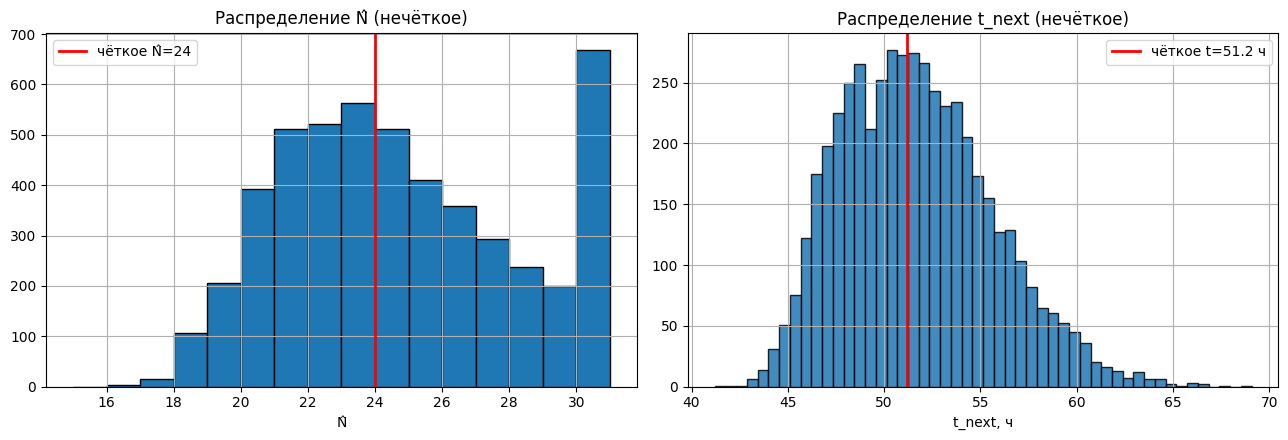

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(N_arr, bins=range(int(N_arr.min())-1, int(N_arr.max())+2), edgecolor='black')
ax[0].axvline(N0, color='red', lw=2, label=f'чёткое N̂={N0}')
ax[0].set_title('Распределение N̂ (нечёткое)')
ax[0].set_xlabel('N̂'); ax[0].legend()

ax[1].hist(t_arr, bins=50, edgecolor='black', alpha=0.85)
ax[1].axvline(t0, color='red', lw=2, label=f'чёткое t={t0:.1f} ч')
ax[1].set_title('Распределение t_next (нечёткое)')
ax[1].set_xlabel('t_next, ч'); ax[1].legend()
plt.tight_layout(); plt.show()


## Часть 2. Нечёткая модель Ла Падула

Каждое $m_i$ → $\mathcal{N}(m_i, 0.1 m_i)$. $N$ раз сэмплируем, делаем линейную регрессию $R_i = R(\infty) - A/i$, получаем распределения $R(\infty)$ и $A$.

In [6]:
def la_padula(m, S=100):
    R = 1 - m/S
    ii = np.arange(1, len(m)+1, dtype=float)
    x = -1.0/ii; y = R
    b1, b0 = np.polyfit(x, y, 1)
    return b0, b1   # R_inf, A

R0, A0 = la_padula(m_orig)
print(f'Чёткий расчёт: R(∞) = {R0:.4f}, A = {A0:.4f}')

# Нечёткий MC
sigmas_m = CV * m_orig
out_R, out_A = [], []
for _ in range(M):
    m_fuzzy = rng.normal(m_orig, np.maximum(sigmas_m, 0.5))
    m_fuzzy = np.maximum(m_fuzzy, 0)
    R_inf, A_ = la_padula(m_fuzzy)
    out_R.append(R_inf); out_A.append(A_)
out_R = np.array(out_R); out_A = np.array(out_A)

print(f'Нечёткий R(∞): {out_R.mean():.4f} ± {out_R.std():.4f}')
print(f'Нечёткий A:    {out_A.mean():.4f} ± {out_A.std():.4f}')


Чёткий расчёт: R(∞) = 0.8185, A = -0.0837
Нечёткий R(∞): 0.8182 ± 0.0071
Нечёткий A:    -0.0838 ± 0.0117


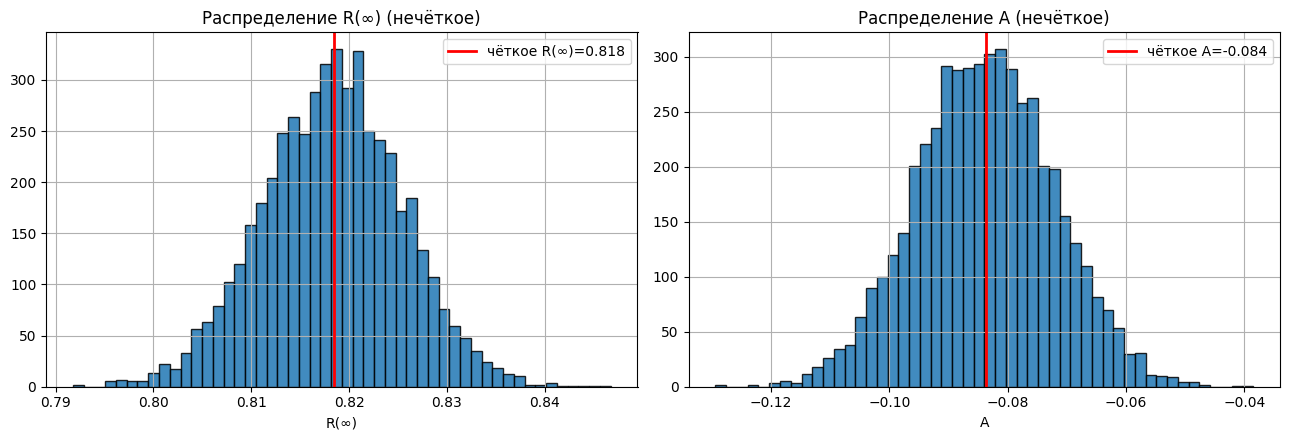

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(out_R, bins=50, edgecolor='black', alpha=0.85)
ax[0].axvline(R0, color='red', lw=2, label=f'чёткое R(∞)={R0:.3f}')
ax[0].set_title('Распределение R(∞) (нечёткое)')
ax[0].set_xlabel('R(∞)'); ax[0].legend()

ax[1].hist(out_A, bins=50, edgecolor='black', alpha=0.85)
ax[1].axvline(A0, color='red', lw=2, label=f'чёткое A={A0:.3f}')
ax[1].set_title('Распределение A (нечёткое)')
ax[1].set_xlabel('A'); ax[1].legend()
plt.tight_layout(); plt.show()


In [8]:
# Доверительные интервалы по уровням принадлежности (α-срезы)
def interval_at_level(arr, alpha):
    """Альфа-срез для гауссоподобной выборки: квантильный интервал."""
    q_lo = np.quantile(arr, alpha/2)
    q_hi = np.quantile(arr, 1 - alpha/2)
    return q_lo, q_hi

print('α-уровни принадлежности для t_next (J-M):')
for alpha in [0.5, 0.32, 0.05]:
    lo, hi = interval_at_level(t_arr, alpha)
    print(f'  α = {alpha:.2f}:  [{lo:.2f}, {hi:.2f}] ч')

print('\nα-уровни для R(∞) (Ла Падула):')
for alpha in [0.5, 0.32, 0.05]:
    lo, hi = interval_at_level(out_R, alpha)
    print(f'  α = {alpha:.2f}:  [{lo:.4f}, {hi:.4f}]')


α-уровни принадлежности для t_next (J-M):
  α = 0.50:  [48.65, 54.22] ч
  α = 0.32:  [47.65, 55.67] ч
  α = 0.05:  [45.31, 60.18] ч

α-уровни для R(∞) (Ла Падула):
  α = 0.50:  [0.8134, 0.8231]
  α = 0.32:  [0.8111, 0.8254]
  α = 0.05:  [0.8042, 0.8322]


## Выводы

1. **Превращение чётких чисел в нечёткие** заменяет «единственное точное значение» на распределение возможных значений вокруг него. Это честный способ учесть неопределённость измерений.

2. **Модель Дж-М** оказывается умеренно чувствительной к шуму в $T_i$: при CV=0.1 значение $\hat N$ может «гулять» на ±1–2 ошибки. Прогноз $t_\text{next}$ имеет относительный разброс примерно такого же порядка (~10%).

3. **Модель Ла Падула** — это линейная регрессия, поэтому её результат хорошо ведёт себя при гауссовом шуме: $R(\infty)$ и $A$ имеют гладкие, симметричные распределения. Можно построить **α-срезы** — это аналоги доверительных интервалов в нечёткой математике.

4. **Практический смысл.** Нечёткий подход даёт не одно число, а интервал «правдоподобных» значений. Это надёжнее для принятия решений — например, «t_next с 95% уровнем принадлежности лежит в [40, 65] часов».
